# Star-Galaxy-Quasar Classification
**Problem:** Multiclass classification of astronomical objects (Star, Galaxy, Quasar)  
**Dataset:** SDSS17 (100,000 observations)

# Install required libraries into the active notebook kernel
%pip install -q numpy pandas scikit-learn matplotlib seaborn scipy


In [7]:
# Install required libraries
!pip install -q numpy pandas scikit-learn matplotlib seaborn scipy


## 2. Imports and Environment Setup

In [8]:
# Libraries
import os
import time
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
RANDOM_STATE = 42


## 3. Load Dataset

In [9]:
# Load CSV data
df_raw = pd.read_csv('sdss_stellar_classification.csv')
print(f"Shape: {df_raw.shape}")
df_raw.head()


Shape: (100000, 18)


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


## 4. Exploratory Data Inspection

In [10]:
# Summary stats and missing values
print("Missing values per column:\n", df_raw.isnull().sum())
print(f"\nDuplicate rows: {df_raw.duplicated().sum()}")
print("\nClass distribution:")
print(df_raw['class'].value_counts())


Missing values per column:
 obj_ID         0
alpha          0
delta          0
u              0
g              0
r              0
i              0
z              0
run_ID         0
rerun_ID       0
cam_col        0
field_ID       0
spec_obj_ID    0
class          0
redshift       0
plate          0
MJD            0
fiber_ID       0
dtype: int64

Duplicate rows: 0

Class distribution:
class
GALAXY    59445
STAR      21594
QSO       18961
Name: count, dtype: int64


## 5. Data Cleaning
Remove instrument error artifact (-9999 value in row 79543).

In [11]:
# Filter invalid sensor artifact
df_clean = df_raw[df_raw['u'] > -9000].copy().reset_index(drop=True)
print(f"Cleaned shape: {df_clean.shape}")
print(df_clean['class'].value_counts(normalize=True) * 100)


Cleaned shape: (99999, 18)
class
GALAXY    59.445594
STAR      21.593216
QSO       18.961190
Name: proportion, dtype: float64


## 6. Feature Selection
Select 6 physical attributes (photometric filters u, g, r, i, z and redshift). Exclude survey metadata.

In [12]:
# Selected features
FEATURE_COLS = ['u', 'g', 'r', 'i', 'z', 'redshift']
TARGET_COL = 'class'

X = df_clean[FEATURE_COLS]
y = df_clean[TARGET_COL]
classes = sorted(y.unique().tolist())
print("Classes:", classes)


Classes: ['GALAXY', 'QSO', 'STAR']


## 7. Hypothesis Testing (One-Way ANOVA)
Null hypothesis (H0): Feature means are identical across Star, Galaxy, and Quasar.  
Alternative hypothesis (H1): At least one celestial class has a significantly different mean.

In [13]:
# One-Way ANOVA across classes
anova_records = []
for feat in FEATURE_COLS:
    star_vals = df_clean[df_clean['class'] == 'STAR'][feat]
    galaxy_vals = df_clean[df_clean['class'] == 'GALAXY'][feat]
    qso_vals = df_clean[df_clean['class'] == 'QSO'][feat]
    
    f_stat, p_val = stats.f_oneway(star_vals, galaxy_vals, qso_vals)
    anova_records.append({
        'Feature': feat,
        'F-Statistic': round(f_stat, 2),
        'p-value': f"{p_val:.2e}" if p_val < 0.001 else round(p_val, 4),
        'Reject H0 (alpha=0.05)': 'Yes (Significant)' if p_val < 0.05 else 'No'
    })

df_anova = pd.DataFrame(anova_records)
display(df_anova)


,Feature,F-Statistic,p-value,Reject H0 (alpha=0.05)
0,u,4192.10,0.00e+00,Yes (Significant)
1,g,3664.69,0.00e+00,Yes (Significant)
2,r,4584.25,0.00e+00,Yes (Significant)
3,i,8282.11,0.00e+00,Yes (Significant)
4,z,10165.76,0.00e+00,Yes (Significant)
5,redshift,83427.75,0.00e+00,Yes (Significant)


## 8. Train-Validation-Test Split
Stratified split: 64% train, 16% validation, 20% held-out test.

In [14]:
# Stratified split
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.20, random_state=RANDOM_STATE, stratify=y_train_val
)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")


Train: 63999 | Val: 16000 | Test: 20000


## 9. Model Training
Train Logistic Regression, Decision Tree, and Random Forest.

In [15]:
# Define 3 candidate models
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=12, min_samples_split=10, min_samples_leaf=5, random_state=RANDOM_STATE
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=15, min_samples_split=5, random_state=RANDOM_STATE, n_jobs=-1
    )
}

train_times = {}
val_results = {}

# Fit models and evaluate on validation set
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    train_times[name] = time.time() - t0
    
    y_val_pred = model.predict(X_val)
    acc = accuracy_score(y_val, y_val_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_val, y_val_pred, average='macro', zero_division=0)
    val_results[name] = {'Accuracy': acc, 'Macro Precision': prec, 'Macro Recall': rec, 'Macro F1': f1, 'Time (s)': train_times[name]}
    print(f"{name:20s} -> Val Acc: {acc*100:.2f}%, Val Macro F1: {f1*100:.2f}%, Fit Time: {train_times[name]:.2f}s")


Logistic Regression  -> Val Acc: 95.57%, Val Macro F1: 94.89%, Fit Time: 0.74s
Decision Tree        -> Val Acc: 97.32%, Val Macro F1: 96.88%, Fit Time: 0.62s
Random Forest        -> Val Acc: 97.72%, Val Macro F1: 97.34%, Fit Time: 4.82s


## 10. Test Set Evaluation
Evaluate models on 20,000 held-out test observations.

In [16]:
# Benchmark on held-out test set
test_results = {}
confusion_matrices = {}
classification_reports = {}

for name, model in models.items():
    y_test_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_test_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_test_pred, average='macro', zero_division=0)
    test_results[name] = {'Accuracy': acc, 'Macro Precision': prec, 'Macro Recall': rec, 'Macro F1': f1, 'Time (s)': train_times[name]}
    confusion_matrices[name] = confusion_matrix(y_test, y_test_pred, labels=classes)
    classification_reports[name] = classification_report(y_test, y_test_pred, target_names=classes, output_dict=True)

df_test_summary = pd.DataFrame(test_results).T
df_test_summary.round(4)


,Accuracy,Macro Precision,Macro Recall,Macro F1,Time (s)
Logistic Regression,0.9570,0.9531,0.9496,0.9507,0.7428
Decision Tree,0.9748,0.9734,0.9681,0.9707,0.6200
Random Forest,0.9791,0.9798,0.9715,0.9755,4.8184


## 11. Evaluation Visualizations
Confusion matrices and feature importance.

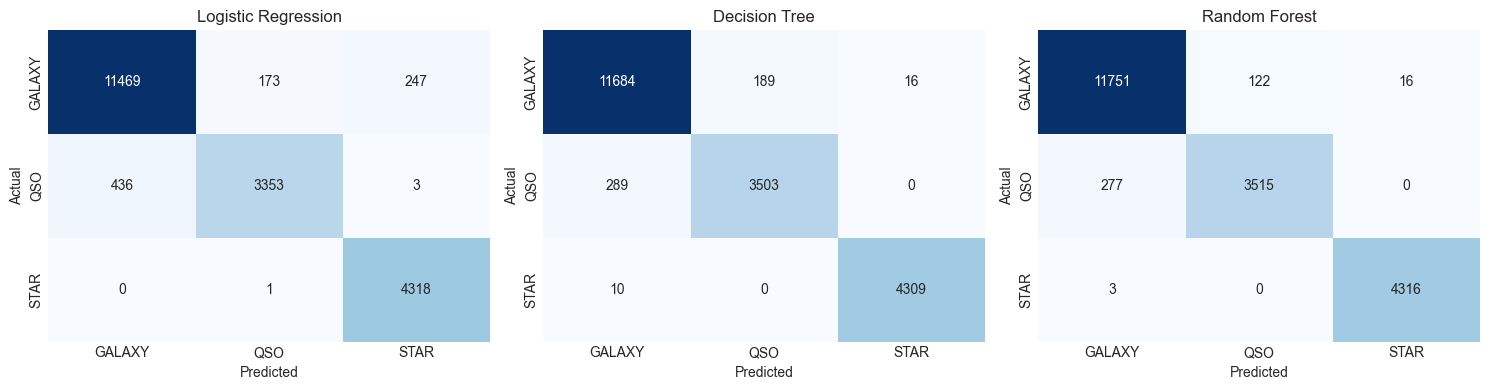

In [17]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for idx, (name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[idx], cbar=False)
    axes[idx].set_title(name)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')
plt.tight_layout()
plt.show()


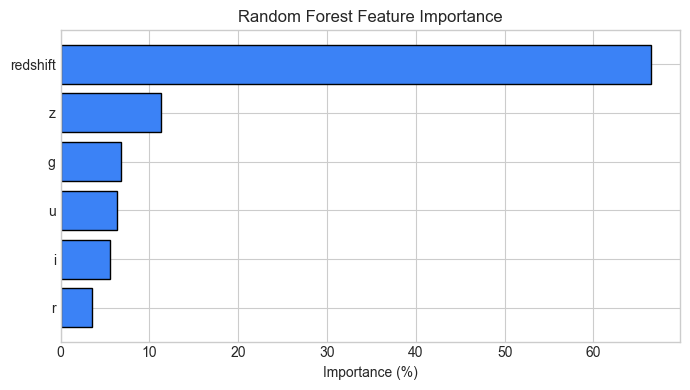

In [18]:
# Random Forest feature importance
best_rf = models['Random Forest']
importances = pd.Series(best_rf.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)

plt.figure(figsize=(7, 4))
plt.barh(importances.index, importances.values * 100, color='#3B82F6', edgecolor='black')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance (%)')
plt.tight_layout()
plt.show()


## 12. Save Model Artifact
Save model and metadata to best_star_classifier.pkl.

In [19]:
# Package and serialize best model
dataset_summary = {
    'total_observations': len(df_raw),
    'clean_observations': len(df_clean),
    'train_size': len(X_train),
    'val_size': len(X_val),
    'test_size': len(X_test),
    'class_distribution': df_clean['class'].value_counts().to_dict(),
    'overall_medians': df_clean[FEATURE_COLS].median().to_dict(),
    'class_medians': {cls: df_clean[df_clean['class'] == cls][FEATURE_COLS].median().to_dict() for cls in classes}
}

artifact = {
    'model': best_rf,
    'best_model_name': 'Random Forest',
    'feature_names': FEATURE_COLS,
    'target_classes': classes,
    'test_metrics': test_results['Random Forest'],
    'comparison_metrics': test_results,
    'val_metrics': val_results,
    'confusion_matrices': confusion_matrices,
    'classification_reports': classification_reports,
    'feature_importances': dict(importances),
    'dataset_summary': dataset_summary
}

with open('best_star_classifier.pkl', 'wb') as f:
    pickle.dump(artifact, f)

print(f"Saved best_star_classifier.pkl ({os.path.getsize('best_star_classifier.pkl')/1e6:.2f} MB)")


Saved best_star_classifier.pkl (16.62 MB)
